## Classifier

General idea : Predict the danger level of a circulation accident

In [1]:
import geopandas as gpd
import pandas as pd
import sklearn

In [2]:
df = gpd.read_file("data/accidents.shz")
df

,DATE,HEURE,CAUSE,TUES,BLESSES_GR,BLESSES_LE,DOMMAGES_M,METEO,ETAT_ROUTE,EMPLACEMEN,...,VITESSE_MA,LOCALITE,PRIORITE,ECLAIRAGE,LUMIERE,TRAFIC,GRAVITE_VA,TYPE_VALEU,TYPE_COMPL,geometry
0,20110102230000,18991230160000,manque d'égards en changeant de voie,0,0,0,3000,beau,sèche,giratoire,...,50.0,à l'intérieur d'une localité,aucune intersection,en service,aurore / crépuscule,normale,Dommages matériels,Accident lors de dépassement ou lors d'un chan...,Collision lors du changement de voie vers la g...,POINT (2570908 1162681)
1,20110104230000,18991230123500,inadaptée aux conditions de la route (mouillée...,0,0,0,1000,beau,verglacée,virage,...,80.0,à l'extérieur d'une localité,aucune intersection,aucun,jour,faible,Dommages matériels,Collision frontale,Frôlement avec le trafic venant en sens invers...,POINT (2568472 1166525)
2,20110104230000,18991230211500,"arrêt (freinage) sans raison sur la chaussée, ...",0,0,0,5000,couvert,sèche,ligne droite,...,50.0,à l'extérieur d'une localité,aucune intersection,en service,nuit,faible,Dommages matériels,Accident par tamponnement,Collision avec un véhicule en marche,POINT (2579634 1183736)
3,20110105230000,18991230063000,inadaptée aux conditions de la route (mouillée...,0,0,0,1500,pluie givrante,verglacée,virage,...,50.0,à l'intérieur d'une localité,aucune intersection,en service,aurore / crépuscule,faible,Dommages matériels,Dérapage ou perte de maîtrise,Collision avec un obstacle hors de la chaussée,POINT (2575732 1201401)
4,20110106230000,18991230161000,non-respect du signal de priorité «cédez le pa...,0,0,0,5000,couvert,humide,intersection,...,80.0,à l'extérieur d'une localité,signal «cédez le passage»,aucun,nuit,forte,Dommages matériels,Accident en s'engageant sur une route,Collision en obliquant à gauche avec le trafic...,POINT (2580788 1201641)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18586,20171024220000,18991230110000,autre attitude fautive lors des mouvements dan...,0,0,0,2000,beau,sèche,place de stationnement,...,50.0,à l'intérieur d'une localité,aucune intersection,hors service,jour,faible,Dommages matériels,Accident lors du stationnement,Avec violation de l'obligation de déclarer,POINT (2578230 1183912)
18587,20180107230000,18991230030000,présence d'animaux sauvages sur la chaussée,0,0,0,2000,couvert,sèche,ligne droite,...,120.0,à l'extérieur d'une localité,aucune intersection,aucun,nuit,faible,Dommages matériels,Accident impliquant un animal,Collision avec du gibier (G),POINT (2559620 1153696)
18588,20230730220000,18991230114400,marche arrière imprudente,0,0,0,5000,beau,sèche,place de stationnement,...,50.0,à l'intérieur d'une localité,aucune intersection,hors service,jour,faible,Dommages matériels,Accident lors du stationnement,Collision avec un obstacle fixe (y compris véh...,POINT (2569312 1156707)
18589,20231107230000,18991230100000,cause inconnue,0,0,0,500,beau,sèche,giratoire,...,50.0,à l'intérieur d'une localité,aucune intersection,hors service,jour,normale,Dommages matériels,Dérapage ou perte de maîtrise,Collision avec un autre usager (piéton y compris),POINT (2578217 1185451)


In [3]:
print(df.columns)
df.shape

Index(['DATE', 'HEURE', 'CAUSE', 'TUES', 'BLESSES_GR', 'BLESSES_LE',
       'DOMMAGES_M', 'METEO', 'ETAT_ROUTE', 'EMPLACEMEN', 'GENRE_ROUT',
       'VITESSE_MA', 'LOCALITE', 'PRIORITE', 'ECLAIRAGE', 'LUMIERE', 'TRAFIC',
       'GRAVITE_VA', 'TYPE_VALEU', 'TYPE_COMPL', 'geometry'],
      dtype='str')


(18591, 21)

In [4]:
df.dtypes

DATE               str
HEURE              str
CAUSE              str
TUES             int64
BLESSES_GR       int64
BLESSES_LE       int64
DOMMAGES_M       int64
METEO              str
ETAT_ROUTE         str
EMPLACEMEN         str
GENRE_ROUT         str
VITESSE_MA     float64
LOCALITE           str
PRIORITE           str
ECLAIRAGE          str
LUMIERE            str
TRAFIC             str
GRAVITE_VA         str
TYPE_VALEU         str
TYPE_COMPL         str
geometry      geometry
dtype: object

In [5]:
df.isna().sum()
df.dropna(inplace=True)
df.isna().sum()

DATE          0
HEURE         0
CAUSE         0
TUES          0
BLESSES_GR    0
BLESSES_LE    0
DOMMAGES_M    0
METEO         0
ETAT_ROUTE    0
EMPLACEMEN    0
GENRE_ROUT    0
VITESSE_MA    0
LOCALITE      0
PRIORITE      0
ECLAIRAGE     0
LUMIERE       0
TRAFIC        0
GRAVITE_VA    0
TYPE_VALEU    0
TYPE_COMPL    0
geometry      0
dtype: int64

In [6]:

#Drop columns with informations we could not get
#TODO : SEE AGAINM WHICH COLUMNS TO DROP; MIGHT BE KEEP SOME OF THEM BY USING THE INFOS OF RETRANSCRIPTION ?'TYPE_VALEU'
COLUMNS_TO_DROP = ['DOMMAGES_M', 'PRIORITE', 'TYPE_COMPL','TYPE_VALEU',  'GRAVITE_VA']

if all(col in df.columns for col in COLUMNS_TO_DROP):
    df.drop(columns=COLUMNS_TO_DROP, inplace=True)

df.describe()


,TUES,BLESSES_GR,BLESSES_LE,VITESSE_MA
count,14311.000000,14311.000000,14311.000000,14311.000000
mean,0.009573,0.146111,0.589896,64.471595
std,0.107603,0.389187,0.796046,23.553644
min,0.000000,0.000000,0.000000,5.000000
25%,0.000000,0.000000,0.000000,50.000000
50%,0.000000,0.000000,0.000000,50.000000
75%,0.000000,0.000000,1.000000,80.000000
max,4.000000,5.000000,15.000000,120.000000


In [7]:
#get unique values for each column
#REMOVED FROM THE LIST : 'ETAT_ROUTE', 'PRIORITE', 'ECLAIRAGE', , 'TYPE_VALEU', 'TYPE_COMPL', 'GRAVITE_VA', 'TYPE_VALEU'
UNIQUE_COLUMNS_TO_CHECK = ['METEO', 'EMPLACEMEN', 'GENRE_ROUT', 'LOCALITE',  'ECLAIRAGE', 'LUMIERE', 'TRAFIC', 'ETAT_ROUTE']
for col in UNIQUE_COLUMNS_TO_CHECK:
    print(f"Unique values for column {col}: {df[col].unique()}\n")

Unique values for column METEO: <StringArray>
[          'beau',        'couvert', 'pluie givrante',          'autre',
          'pluie', 'chute de neige',          'grêle']
Length: 7, dtype: str

Unique values for column EMPLACEMEN: <StringArray>
[             'giratoire',                 'virage',           'ligne droite',
           'intersection', 'place de stationnement',                  'place',
                  'autre',          'aire de repos']
Length: 8, dtype: str

Unique values for column GENRE_ROUT: <StringArray>
[                 'route principale',                  'route secondaire',
                         'autoroute',                             'autre',
 'installation annexe sur autoroute',                    'semi-autoroute']
Length: 6, dtype: str

Unique values for column LOCALITE: <StringArray>
['à l'intérieur d'une localité', 'à l'extérieur d'une localité']
Length: 2, dtype: str

Unique values for column ECLAIRAGE: <StringArray>
['en service', 'aucun', 'hors se

In [8]:
from sklearn.preprocessing import OneHotEncoder
#convert date to datetime
df_cleaned = df.copy()
df_cleaned['DATE'] = pd.to_datetime(df['DATE'].str[:8], format='%Y%m%d')
heure_str = df['HEURE'].str[-6:]
df_cleaned['HEURE'] = pd.to_datetime(heure_str, format='%H%M%S').dt.hour
print(df_cleaned['HEURE'].head())


df_cleaned.drop(columns=['DATE', 'CAUSE'], inplace=True)

categorical_cols = df_cleaned.select_dtypes(include=['object']).columns

encoder = OneHotEncoder(sparse_output=False, drop='first')
encoded_features = encoder.fit_transform(df_cleaned[categorical_cols])

encoded_df = pd.DataFrame(
    encoded_features, 
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df_cleaned.index
)

df_final = pd.concat([df_cleaned.drop(columns=categorical_cols), encoded_df], axis=1)
df_final.loc[df_final['TUES'] >= 1, 'TUES'] = 1
df_final.loc[df_final['BLESSES_LE'] >= 1, 'BLESSES_LE'] = 1
df_final.loc[df_final['BLESSES_GR'] >= 1, 'BLESSES_GR'] = 1
df_final.describe()


0    16
1    12
2    21
3     6
4    16
Name: HEURE, dtype: int32


C:\Users\gaeta\AppData\Local\Temp\ipykernel_11700\3486961159.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_cleaned.select_dtypes(include=['object']).columns


,HEURE,TUES,BLESSES_GR,BLESSES_LE,VITESSE_MA,METEO_beau,METEO_chute de neige,METEO_couvert,METEO_grêle,METEO_pluie,...,ECLAIRAGE_en service,ECLAIRAGE_hors service,LUMIERE_inconnu,LUMIERE_jour,LUMIERE_nuit,TRAFIC_faible,TRAFIC_file arrêtée,TRAFIC_file ralentie,TRAFIC_forte,TRAFIC_normale
count,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,...,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000
mean,12.523164,0.008804,0.135281,0.464817,64.471595,0.620292,0.031584,0.228496,0.001887,0.096359,...,0.183216,0.241842,0.002446,0.662777,0.256656,0.433722,0.011949,0.018797,0.109077,0.418909
std,5.386437,0.093421,0.342035,0.498778,23.553644,0.485331,0.174896,0.419878,0.043396,0.295094,...,0.386857,0.428214,0.049395,0.472778,0.436803,0.495605,0.108660,0.135811,0.311747,0.493398
min,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,9.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,13.000000,0.000000,0.000000,0.000000,50.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,16.000000,0.000000,0.000000,1.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
max,23.000000,1.000000,1.000000,1.000000,120.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [9]:
#TODO: SEE IF WE COULD KEEP IT FOR FURTHER VISUALIZATION....
df_final.drop('geometry', inplace=True, axis=1)

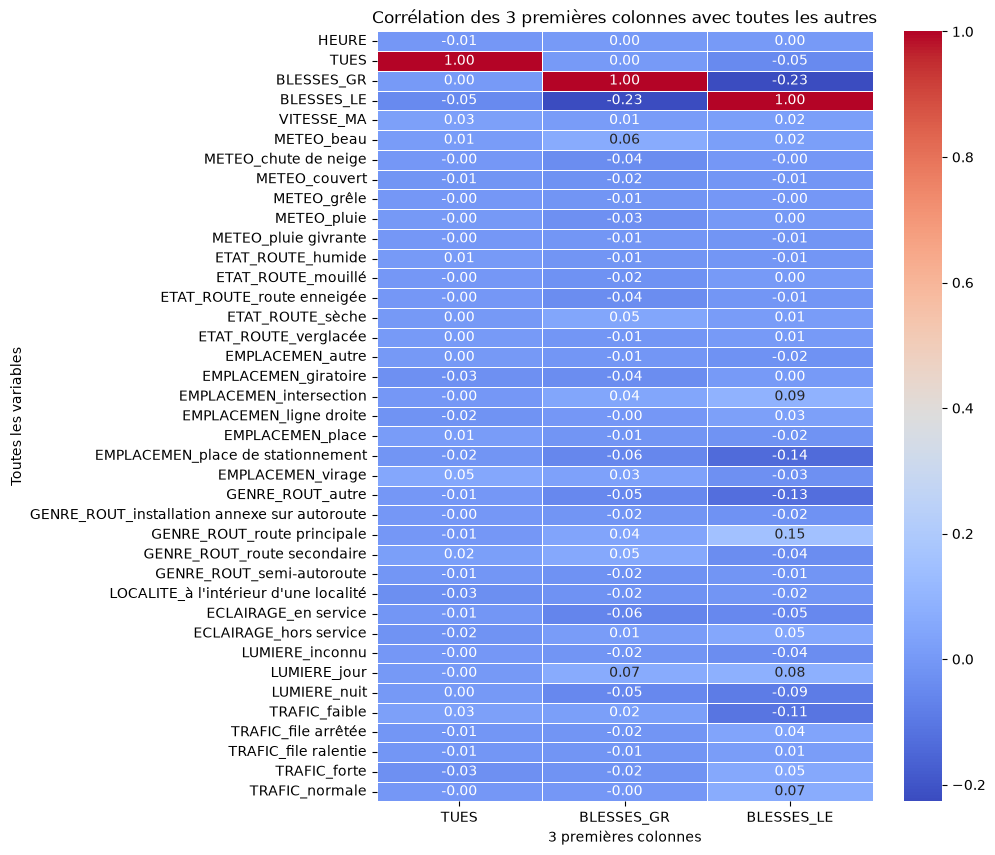

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Sélectionner toutes les lignes (variables) et les 3 premières colonnes
corr_subset = df_final.corr(method='kendall').loc[:, ['TUES', 'BLESSES_GR', 'BLESSES_LE']]

# Création de la figure
plt.figure(figsize=(8, 10)) # Ajuste la taille selon le nombre total de variables
sns.heatmap(
    corr_subset, 
    annot=True,       # Affiche les valeurs numériques dans les cases
    cmap="coolwarm",  # Palette de couleurs (bleu = négatif, rouge = positif)
    fmt=".2f",        # Format des nombres (2 décimales)
    linewidths=0.5,   # Lignes de séparation entre les cellules
    cbar=True         # Barre de couleur sur le côté
)

plt.title("Corrélation des 3 premières colonnes avec toutes les autres", fontsize=12)
plt.xlabel("3 premières colonnes")
plt.ylabel("Toutes les variables")
plt.show()

In [11]:
import numpy as np

print("Total accidents by class")
print("Tué: ", df_final['TUES'].sum())
print("Grave: ", df_final['BLESSES_GR'].sum())
print("Leger: ", df_final['BLESSES_LE'].sum(), "\n")

#IT'S ORDERED BTW
conditions = [
    (df_final['TUES'] > 0),
    (df_final['BLESSES_GR'] > 0),
    (df_final['BLESSES_LE'] > 0)
]

choices = [3, 2, 1]

#0 if no victime of any sort
new_df = df_final.copy()
new_df['VICTIME'] = np.select(conditions, choices, default=0)
new_df.drop(columns=['TUES','BLESSES_GR','BLESSES_LE'], inplace=True)
print(new_df['VICTIME'].value_counts())

df_final.describe()

Total accidents by class
Tué:  126
Grave:  1936
Leger:  6652 

VICTIME
1    6287
0    5981
2    1917
3     126
Name: count, dtype: int64


,HEURE,TUES,BLESSES_GR,BLESSES_LE,VITESSE_MA,METEO_beau,METEO_chute de neige,METEO_couvert,METEO_grêle,METEO_pluie,...,ECLAIRAGE_en service,ECLAIRAGE_hors service,LUMIERE_inconnu,LUMIERE_jour,LUMIERE_nuit,TRAFIC_faible,TRAFIC_file arrêtée,TRAFIC_file ralentie,TRAFIC_forte,TRAFIC_normale
count,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,...,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000,14311.000000
mean,12.523164,0.008804,0.135281,0.464817,64.471595,0.620292,0.031584,0.228496,0.001887,0.096359,...,0.183216,0.241842,0.002446,0.662777,0.256656,0.433722,0.011949,0.018797,0.109077,0.418909
std,5.386437,0.093421,0.342035,0.498778,23.553644,0.485331,0.174896,0.419878,0.043396,0.295094,...,0.386857,0.428214,0.049395,0.472778,0.436803,0.495605,0.108660,0.135811,0.311747,0.493398
min,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,9.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,13.000000,0.000000,0.000000,0.000000,50.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,16.000000,0.000000,0.000000,1.000000,80.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
max,23.000000,1.000000,1.000000,1.000000,120.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [12]:
from sklearn.feature_selection import mutual_info_classif

X = new_df.drop(columns=['VICTIME'])
mi = mutual_info_classif(X, new_df['VICTIME'], discrete_features=True, random_state=0)
print(pd.Series(mi, index=X.columns).sort_values(ascending=False).head(15))

VITESSE_MA                           0.019429
EMPLACEMEN_place de stationnement    0.015365
GENRE_ROUT_route principale          0.014413
HEURE                                0.013568
GENRE_ROUT_autre                     0.012362
LUMIERE_jour                         0.008117
LUMIERE_nuit                         0.007972
EMPLACEMEN_intersection              0.007025
TRAFIC_faible                        0.005669
ECLAIRAGE_en service                 0.004548
METEO_beau                           0.002967
ECLAIRAGE_hors service               0.002285
TRAFIC_normale                       0.002215
TRAFIC_forte                         0.001920
EMPLACEMEN_virage                    0.001615
dtype: float64


In [13]:
#train_val_test split
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

X_train, X_test, y_train, y_test = train_test_split(df_final.drop(columns=['TUES','BLESSES_GR','BLESSES_LE']), df_final[['TUES', 'BLESSES_GR', 'BLESSES_LE']], test_size=0.4, random_state=42)

tues_train = y_train['TUES']
graves_train = y_train['BLESSES_GR']
legers_train = y_train['BLESSES_LE']

total_tues = tues_train.sum()
total_graves = graves_train.sum()
total_legers = legers_train.sum()
total_accidents = total_tues + total_graves + total_legers

ratio_leger = total_legers / total_accidents+1e-6
ratio_grave = total_graves / total_accidents+1e-6
ratio_tue = total_tues / total_accidents+1e-6

print(f"RATIO LEGERS : {ratio_leger}")
print(f"RATIO GRAVES : {ratio_grave}")
print(f"RATIO TUES : {ratio_tue}")

sample_weights = (
    1.0
    + (y_train['BLESSES_LE'] * ratio_leger)
    + (y_train['BLESSES_GR'] * ratio_grave)
    + (y_train['TUES'] * ratio_tue)
)


RATIO LEGERS : 0.764673256097561
RATIO GRAVES : 0.22103758536585366
RATIO TUES : 0.014292158536585366


In [14]:
from sklearn.model_selection import GridSearchCV

def find_best_hyperparameters(regressor, param_grid, X_train, y_train, scoring = 'r2', sample_weights = None):
    grid_search = GridSearchCV(regressor, param_grid, cv=5, scoring=scoring, return_train_score=True, n_jobs=-1, verbose=2) # use all the cores of the CPU
    grid_search.fit(X_train, y_train, sample_weight=sample_weights)
    print("Best hyperparameters: {}".format(grid_search.best_params_))
    print("Best score (r2): {:.2f}".format(grid_search.best_score_))
    return grid_search.best_estimator_

In [15]:
from sklearn.model_selection import cross_validate
def print_cross_validation_results(regressor, X_train, y_train):
    scoring = ['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error']
    cv_results = cross_validate(regressor, X_train, y_train, cv=5, scoring = scoring, n_jobs=-1, return_train_score=True)
    print("Train R^2: {:.2f}".format(cv_results['train_r2'].mean()))
    print("Validation R^2: {:.2f}".format(cv_results['test_r2'].mean()))
    print("Train MAE: {:.2f}".format(-cv_results['train_neg_mean_absolute_error'].mean()))
    print("Validation MAE: {:.2f}".format(-cv_results['test_neg_mean_absolute_error'].mean()))
    print("Train RMSE: {:.2f}".format(-cv_results['train_neg_root_mean_squared_error'].mean()))
    print("Validation RMSE: {:.2f}".format(-cv_results['test_neg_root_mean_squared_error'].mean()))

In [16]:
# from sklearn.ensemble import RandomForestRegressor

# param_grid = {'n_estimators': [10, 100], 'max_depth': [None, 1, 3,5, 10, 20], 'min_samples_split': [2, 4,8,16, 32], 'min_samples_leaf': [1,2,3,4, 8 ,16]}

# rf_reg = RandomForestRegressor()

# rf_reg = find_best_hyperparameters(rf_reg, param_grid, X_train, y_train, sample_weights=sample_weights)

# print_cross_validation_results(rf_reg, X_train, y_train)

In [17]:
# new_df = df_final.copy()
# new_df = new_df[['VICTIME','ETAT_ROUTE_humide', 'ETAT_ROUTE_mouillé', 'ETAT_ROUTE_route enneigée', 'ETAT_ROUTE_sèche', 'ETAT_ROUTE_verglacée', 'GENRE_ROUT_autre', 'GENRE_ROUT_installation annexe sur autoroute', 'GENRE_ROUT_route principale','GENRE_ROUT_route secondaire', 'GENRE_ROUT_semi-autoroute', 'LUMIERE_inconnu', 'LUMIERE_jour', 'LUMIERE_nuit']]

In [18]:
from sklearn.ensemble import GradientBoostingRegressor

X_train, X_test, y_train, y_test = train_test_split(new_df.drop(columns=['VICTIME']), new_df[['VICTIME']], test_size=0.4, random_state=42)


param_grid = {'n_estimators': [10, 100, 1000], 'learning_rate': [0.1, 0.05, 0.01, 0.001]}

clf = GradientBoostingRegressor(n_estimators=100, learning_rate=1.0,max_depth=1, random_state=0)

clf = find_best_hyperparameters(clf, param_grid, X_train, y_train, sample_weights=sample_weights)
print_cross_validation_results(clf, X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


c:\Users\gaeta\Desktop\HEI\3rd_year\Hackathon_301-302\.venv\Lib\site-packages\sklearn\ensemble\_gb.py:691: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


Best hyperparameters: {'learning_rate': 0.05, 'n_estimators': 1000}
Best score (r2): 0.06
Train R^2: 0.08
Validation R^2: 0.06
Train MAE: 0.56
Validation MAE: 0.56
Train RMSE: 0.69
Validation RMSE: 0.69


In [19]:
# from sklearn.model_selection import cross_val_predict
# from sklearn.metrics import confusion_matrix, balanced_accuracy_score, classification_report

# y_pred = cross_val_predict(clf, new_df.drop(columns=['VICTIME']), new_df['VICTIME'], cv=5)
# print(confusion_matrix(new_df['VICTIME'], y_pred))
# print("Balanced accuracy :", balanced_accuracy_score(new_df['VICTIME'], y_pred))
# print(classification_report(new_df['VICTIME'], y_pred))



In [43]:
BATCH_SIZE = 512
EPOCHS = 30
DROP_OUT = 0.2
ACCURACY_RANGE = 1000

In [28]:

train_losses = []
validation_losses = []


def train(dataloader, model, loss_fn, optimizer):
    model.train()
    train_loss = 0.0

    for X, y in dataloader:
        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
        train_loss += loss.item()

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    return train_loss / len(dataloader)


def test(dataloader, model, loss_fn):
    model.eval()
    test_loss = 0.0

    with torch.no_grad():
        for X, y in dataloader:

            pred = model(X)
            loss = loss_fn(pred, y)
            test_loss += loss.item()

            val_outputs = model(X_val)
            probabilities = torch.softmax(val_outputs, dim=1)
            max_probs, predicted = torch.max(probabilities, dim=1)

            val_outputs = model(X_val)
            val_loss = loss_fct(val_outputs, y_val)
            validation_losses.append(val_loss.item())
            # print(f"Epoch {epoch+1}, Loss: {loss.item()}")


    return max_probs, predicted


{np.int64(0): np.float64(0.5982441471571907), np.int64(1): np.float64(0.5656126482213438), np.int64(2): np.float64(1.8779527559055118), np.int64(3): np.float64(35.775)}
tensor([ 1.0000,  1.3077,  4.5241, 69.9684])
Epoch 1, Loss: 2.133535146713257
Epoch 2, Loss: 2.066899299621582
Epoch 3, Loss: 1.9387069940567017
Epoch 4, Loss: 1.9457954168319702
Epoch 5, Loss: 1.866191029548645
Epoch 6, Loss: 1.6288318634033203
Epoch 7, Loss: 1.6537295579910278
Epoch 8, Loss: 1.6187083721160889
Epoch 9, Loss: 1.6230065822601318
Epoch 10, Loss: 1.619439959526062
Epoch 11, Loss: 1.5770477056503296
Epoch 12, Loss: 1.5292402505874634
Epoch 13, Loss: 1.5150988101959229
Epoch 14, Loss: 1.5427284240722656
Epoch 15, Loss: 1.5180333852767944
Epoch 16, Loss: 1.4985185861587524
Epoch 17, Loss: 1.4835631847381592
Epoch 18, Loss: 1.4799461364746094
Epoch 19, Loss: 1.4831898212432861
Epoch 20, Loss: 1.4490467309951782
Epoch 21, Loss: 1.4396103620529175
Epoch 22, Loss: 1.4163016080856323
Epoch 23, Loss: 1.40101289749

C:\Users\gaeta\AppData\Local\Temp\ipykernel_11700\3058877183.py:80: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


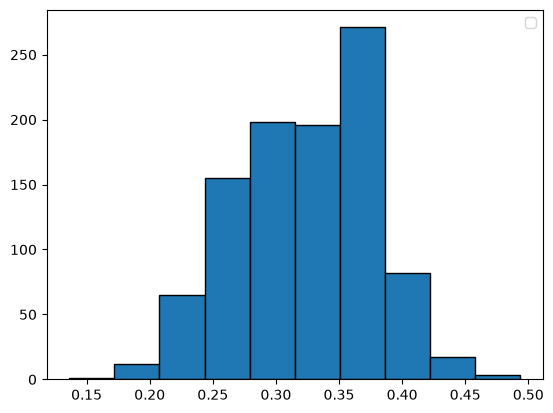

array([0, 1, 1, 0, 1])

In [44]:
#TODO : CHECK ON "MULTI ONE HOT ENCODING", PCA, check linear regression, plot some features with outputs  

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.utils.class_weight import compute_class_weight

X_train, X_temp, y_train, y_temp = train_test_split(new_df.drop(columns=['VICTIME']), new_df[['VICTIME']], test_size=0.8, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

train_dataloader = DataLoader(TensorDataset(torch.tensor(X_train.values, dtype=torch.float32), torch.tensor(y_train.values, dtype=torch.long).squeeze()), batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(TensorDataset(torch.tensor(X_val.values, dtype=torch.float32), torch.tensor(y_val.values, dtype=torch.long).squeeze()), batch_size=BATCH_SIZE, shuffle=False)
test_dataloader = DataLoader(TensorDataset(torch.tensor(X_test.values, dtype=torch.float32), torch.tensor(y_test.values, dtype=torch.long).squeeze()), batch_size=BATCH_SIZE, shuffle=False)

classes = np.unique(y_train)
w = compute_class_weight('balanced', classes=classes, y=y_train.values.ravel())
print(dict(zip(classes, w)))

X_train = torch.tensor(X_train.values, dtype=torch.float32)
X_val = torch.tensor(X_val.values, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.long).squeeze()
y_val = torch.tensor(y_val.values, dtype=torch.long).squeeze()

model = nn.Sequential(
    nn.Linear(X_train.shape[1], 64),
    nn.ReLU(),
    nn.Dropout(DROP_OUT),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(DROP_OUT),
    nn.Linear(32, 4)
)

print(weights := torch.tensor([1.0, 1/ratio_leger, 1/ratio_grave, 1/ratio_tue], dtype=torch.float32))

loss_fct = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 1/ratio_leger, 1/ratio_grave, 1/ratio_tue], dtype=torch.float32))
optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

train, val = [], []
accuracies = []

for i in range(ACCURACY_RANGE):
    for epoch in range(EPOCHS):
        outputs = model(X_train)
        # print(f"Epoch {epoch+1}, Outputs: {outputs}")
        loss = loss_fct(outputs, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train.append(loss.item())
        with torch.no_grad():
            val_outputs = model(X_val)
            val_loss = loss_fct(val_outputs, y_val)
            val.append(val_loss.item())
        print(f"Epoch {epoch+1}, Loss: {loss.item()}")

    # plt.plot(train, label='Train Loss')
    # plt.plot(val, label='Validation Loss')
    # plt.legend()
    # plt.title('Loss over epochs')

    model.eval()

    with torch.no_grad():
        val_outputs = model(X_val)
        
        probabilities = torch.softmax(val_outputs, dim=1)
        
        max_probs, predicted = torch.max(probabilities, dim=1)

    for i in range(5):
        print(f"Accident {i} -> Classe prédite : {predicted[i].item()} (Confiance : {max_probs[i].item() * 100:.1f}%)", probabilities[i].numpy())

    accuracy = (predicted == y_val).sum().item() / y_val.size(0)
    print(f"Validation Accuracy: {accuracy * 100:.2f}%")

    accuracies.append(accuracy)


y_val_np = y_val.numpy()
y_val_np[:5]

32.29%


C:\Users\gaeta\AppData\Local\Temp\ipykernel_11700\188092943.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


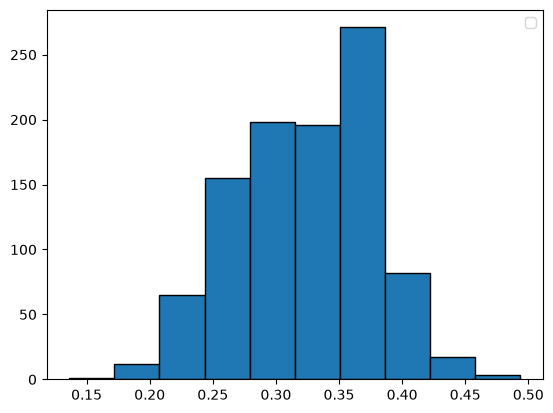

In [47]:
plt.hist(accuracies, edgecolor='black', bins=10)
print(f"{np.mean(accuracies) * 100:.2f}%")
plt.legend()
plt.show()